# Digit Recognizer

## 1. Задача и исследовательская гипотеза

Гипотеза: нелинейные сочетания пикселей помогут уменьшить ошибки распознавания.
Сначала проверим это на MLP, затем сравним её с CNN.

Сейчас обучим логистическую регрессию как baseline для этих сравнений.
Самый частый класс используем для контроля.

In [1]:
import hashlib
import json
import os
import time
import tomllib
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from threadpoolctl import threadpool_limits


In [2]:
ROOT = Path.cwd().resolve()
config_path = ROOT / "baseline.toml"
with config_path.open("rb") as file:
    config = tomllib.load(file)
fraction = config["experiment"]["validation_fraction"]
if not 0 < fraction < 1:
    raise ValueError("validation_fraction должна лежать между 0 и 1.")
if config["model"]["C"] <= 0 or config["model"]["max_iter"] < 1:
    raise ValueError("C и max_iter должны быть положительными.")
if config["runtime"]["threads"] < 1:
    raise ValueError("Число потоков должно быть положительным.")

train_path = ROOT / config["paths"]["train_csv"]
artifact_path = ROOT / config["paths"]["artifact"]
reports_path = ROOT / config["paths"]["reports"]
seed = config["experiment"]["seed"]
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## 2. Проверка данных

Загрузим train.csv и проверим формат, пропуски и диапазоны значений.

In [3]:
pixel_columns = [f"pixel{i}" for i in range(784)]
if not train_path.is_file():
    raise FileNotFoundError("Нужен data/raw/train.csv из Kaggle Digit Recognizer; см. README.")
if pd.read_csv(train_path, nrows=0).columns.tolist() != ["label", *pixel_columns]:
    raise ValueError("Ожидаются колонки label,pixel0,...,pixel783 в указанном порядке.")

data = pd.read_csv(train_path, dtype=np.float32)
values = data.to_numpy()
if len(data) == 0 or not np.isfinite(values).all():
    raise ValueError("Данные должны быть непустыми, без пропусков и бесконечностей.")
if not np.equal(values, np.floor(values)).all():
    raise ValueError("Метки и пиксели должны быть целыми.")
if np.any((values[:, 0] < 0) | (values[:, 0] > 9)):
    raise ValueError("Метки должны быть цифрами 0–9.")
if np.any((values[:, 1:] < 0) | (values[:, 1:] > 255)):
    raise ValueError("Пиксели должны лежать в диапазоне 0–255.")
y = values[:, 0].astype(np.int64)
X = values[:, 1:].astype(np.uint8)
if np.any(np.bincount(y, minlength=10) < 5):
    raise ValueError("Для этого протокола нужно не менее пяти примеров каждой цифры.")
del data, values

digest = hashlib.sha256()
with train_path.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        digest.update(chunk)
data_sha256 = digest.hexdigest()

pd.DataFrame({"Значение": {
    "Изображений": len(y), "Пикселей на изображение": X.shape[1],
    "Минимальный пиксель": int(X.min()), "Максимальный пиксель": int(X.max()),
    "Пропусков": 0,
}})


,Значение
Изображений,42000
Пикселей на изображение,784
Минимальный пиксель,0
Максимальный пиксель,255
Пропусков,0


Проверим точные дубликаты по SHA-256 пикселей.
Если они есть, оставим одинаковые изображения в одной части split.

In [4]:
image_groups = {}
group_labels = {}
groups = np.empty(len(y), dtype=np.int64)
for index, pixels in enumerate(X):
    fingerprint = hashlib.sha256(pixels.tobytes()).digest()
    group = image_groups.setdefault(fingerprint, len(image_groups))
    groups[index] = group
    group_labels.setdefault(group, set()).add(int(y[index]))
duplicate_rows = len(y) - len(image_groups)
conflicting_groups = sum(len(labels) > 1 for labels in group_labels.values())

print(f"Уникальных изображений: {len(image_groups)}")
print(f"Дополнительных строк-дубликатов: {duplicate_rows}")
print(f"Групп одинаковых изображений с разными метками: {conflicting_groups}")


Уникальных изображений: 42000
Дополнительных строк-дубликатов: 0
Групп одинаковых изображений с разными метками: 0


## 3. Валидация

Разделим данные в пропорции 80/20 со стратификацией по цифре, seed=42.
Если найдутся дубликаты, используем групповой split.

Основная метрика — accuracy, дополнительная — macro-F1 (среднее F1 по десяти цифрам).

In [5]:
if duplicate_rows:
    n_splits = round(1 / fraction)
    if n_splits < 2 or not np.isclose(1 / n_splits, fraction):
        raise ValueError("С дубликатами доля validation должна равняться 1 / целое число >= 2.")
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_indices, validation_indices = next(splitter.split(X, y, groups))
    split_method = f"StratifiedGroupKFold: first of {n_splits} folds; identical-image groups"
else:
    train_indices, validation_indices = train_test_split(
        np.arange(len(y)), test_size=fraction, stratify=y, random_state=seed
    )
    split_method = "Stratified train_test_split"

train_indices, validation_indices = np.sort(train_indices), np.sort(validation_indices)
assert not set(train_indices) & set(validation_indices)
assert set(train_indices) | set(validation_indices) == set(range(len(y)))
assert not set(groups[train_indices]) & set(groups[validation_indices])
assert set(y[train_indices]) == set(y[validation_indices]) == set(range(10))
print(split_method)
print(f"Обучение: {len(train_indices)}; валидация: {len(validation_indices)}")
class_counts = pd.DataFrame({
    "train": np.bincount(y[train_indices], minlength=10),
    "validation": np.bincount(y[validation_indices], minlength=10),
}).rename_axis("digit")
class_counts


Stratified train_test_split
Обучение: 33600; валидация: 8400


,train,validation
digit,,
0,3305,827
1,3747,937
2,3342,835
3,3481,870
4,3258,814
5,3036,759
6,3310,827
7,3521,880
8,3250,813


## 4. EDA

Посмотрим на распределение классов и примеры из обучающей части.

[[<matplotlib.axis.XTick at 0x11a8694f0>,
 Text(0.5, 0, 'Digit'),
 Text(0, 0.5, 'Training images'),
 Text(0.5, 1.0, 'Class distribution: train')]

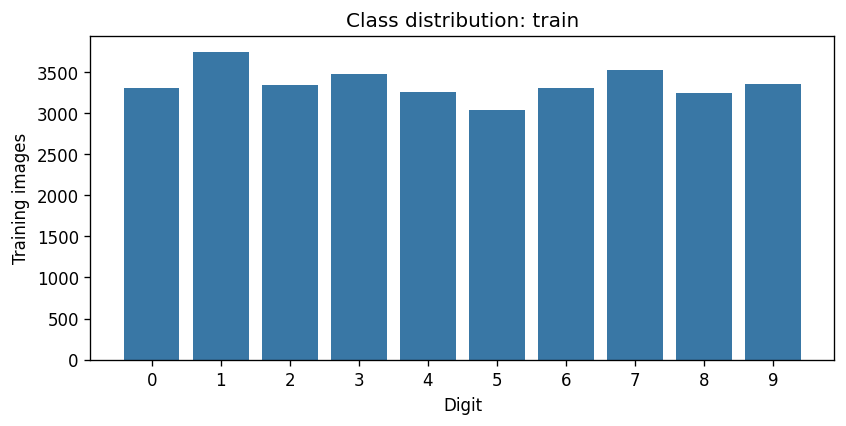

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(10), class_counts["train"], color="#3977a5")
ax.set(xticks=range(10), xlabel="Digit", ylabel="Training images", title="Class distribution: train")


Text(0.5, 0.98, 'Training images: three examples per digit')

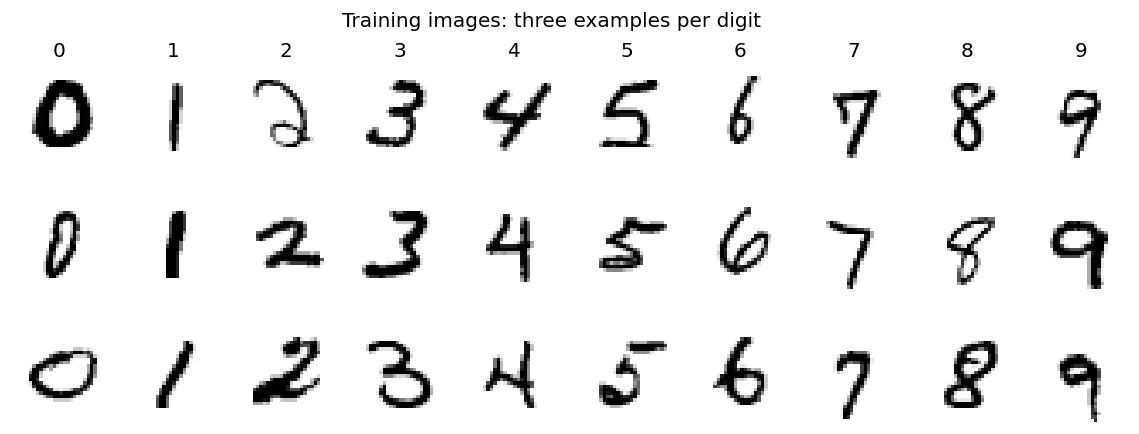

In [7]:
rng = np.random.default_rng(seed)
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for digit in range(10):
    candidates = train_indices[y[train_indices] == digit]
    for row, index in enumerate(rng.choice(candidates, 3, replace=len(candidates) < 3)):
        axes[row, digit].imshow(X[index].reshape(28, 28), cmap="gray_r", vmin=0, vmax=255)
        axes[row, digit].axis("off")
        if row == 0:
            axes[row, digit].set_title(str(digit))
fig.suptitle("Training images: three examples per digit")

Классы примерно сбалансированы. На изображениях различаются наклон и толщина штрихов.

## 5. Обучение

Сравним самый частый класс и логистическую регрессию.
Пиксели делим на 255; параметры модели берём из baseline.toml.

In [8]:
# Одно и то же фиксированное преобразование для обеих частей.
X_train = X[train_indices].astype(np.float64) / 255.0
X_validation = X[validation_indices].astype(np.float64) / 255.0
y_train, y_validation = y[train_indices], y[validation_indices]

In [ ]:
model = LogisticRegression(**config["model"], penalty="l2", random_state=seed)
dummy = DummyClassifier(strategy="most_frequent")

started = time.perf_counter()
with threadpool_limits(limits=config["runtime"]["threads"]):
    dummy.fit(X_train, y_train)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)

if any(issubclass(w.category, ConvergenceWarning) for w in caught):
    raise RuntimeError("Оптимизатор не сошёлся")

training_seconds = time.perf_counter() - started
artifact_path.parent.mkdir(parents=True, exist_ok=True)
checkpoint = {
    "format_version": 2, "model": model, "dummy": dummy,
    "train_indices": train_indices, "validation_indices": validation_indices,
    "split_method": split_method, "data_sha256": data_sha256,
    "config": config,
    "pixel_divisor": 255.0, "training_seconds": training_seconds,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "iterations": model.n_iter_.tolist(), "converged": True,
}
joblib.dump(checkpoint, artifact_path, compress=3)

['/Users/k7ps/vscode_projects/digit_recognizer/artifacts/baseline.joblib']

## 6. Оценка

Загрузим сохранённые модели и посчитаем метрики на validation.

In [10]:
checkpoint = joblib.load(artifact_path)

np.testing.assert_array_equal(checkpoint["validation_indices"], validation_indices)
model, dummy = checkpoint["model"], checkpoint["dummy"]

with threadpool_limits(limits=config["runtime"]["threads"]):
    predicted = model.predict(X_validation)
    probabilities = model.predict_proba(X_validation)
    dummy_predicted = dummy.predict(X_validation)

metrics = {}
for name, labels in [("dummy", dummy_predicted), ("logistic_regression", predicted)]:
    metrics[name] = {
        "accuracy": float(accuracy_score(y_validation, labels)),
        "macro_f1": float(f1_score(y_validation, labels, average="macro", zero_division=0)),
    }

metrics["accuracy_gain_over_dummy"] = metrics["logistic_regression"]["accuracy"] - metrics["dummy"]["accuracy"]
pd.DataFrame({name: metrics[name] for name in ["dummy", "logistic_regression"]}).T


,accuracy,macro_f1
dummy,0.111548,0.020071
logistic_regression,0.913333,0.912139


In [11]:
correct = int(np.sum(predicted == y_validation))
print(f"Верно распознано {correct} из {len(y_validation)} изображений.")

Верно распознано 7672 из 8400 изображений.


In [12]:
per_class = pd.DataFrame(classification_report(
    y_validation, predicted, labels=list(range(10)), output_dict=True, zero_division=0
)).T
per_class.loc[[str(i) for i in range(10)]].round(4)

,precision,recall,f1-score,support
0,0.9554,0.9589,0.9572,827.0
1,0.9346,0.9755,0.9546,937.0
2,0.9114,0.8994,0.9054,835.0
3,0.8966,0.8770,0.8867,870.0
4,0.9190,0.9054,0.9121,814.0
5,0.8725,0.8564,0.8644,759.0
6,0.9522,0.9625,0.9573,827.0
7,0.9296,0.9307,0.9302,880.0
8,0.8797,0.8549,0.8671,813.0
9,0.8737,0.8998,0.8865,838.0


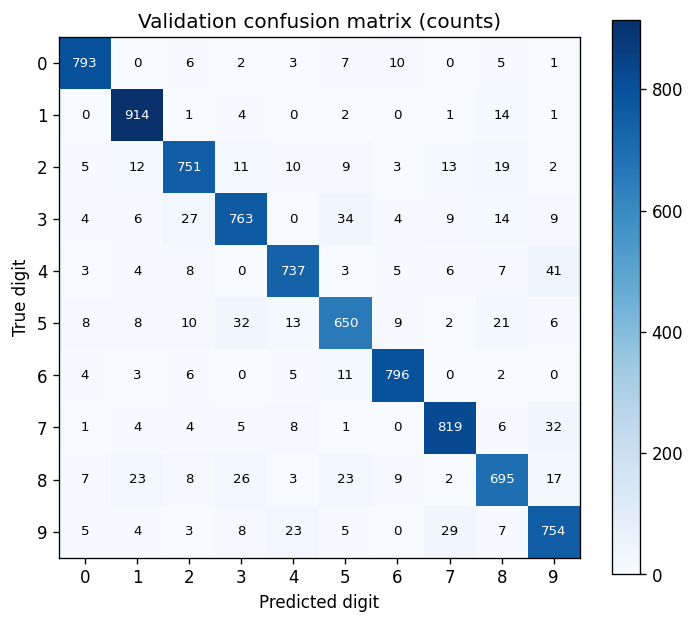

In [13]:
matrix = confusion_matrix(y_validation, predicted, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrix, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8,
                color="white" if matrix[i, j] > matrix.max() / 2 else "black")

ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted digit", ylabel="True digit",
       title="Validation confusion matrix (counts)")
fig.colorbar(image, ax=ax)

## 7. Ошибки

Посмотрим на самые частые пары ошибок и несколько изображений.
row_index — номер строки в исходных данных, начиная с нуля.

In [14]:
predictions = pd.DataFrame({
    "row_index": validation_indices, "true_label": y_validation,
    "predicted_label": predicted, "confidence": probabilities.max(axis=1),
    "dummy_label": dummy_predicted,
})
errors = predictions[predictions.true_label != predictions.predicted_label]
pairs = sorted(
    [(int(matrix[i, j]), i, j) for i in range(10) for j in range(10) if i != j and matrix[i, j]],
    key=lambda item: (-item[0], item[1], item[2]),
)[:3]
pd.DataFrame([
    {"Истинная цифра": i, "Предсказанная цифра": j, "Ошибок": count} for count, i, j in pairs
])

,Истинная цифра,Предсказанная цифра,Ошибок
0,4,9,41
1,3,5,34
2,5,3,32


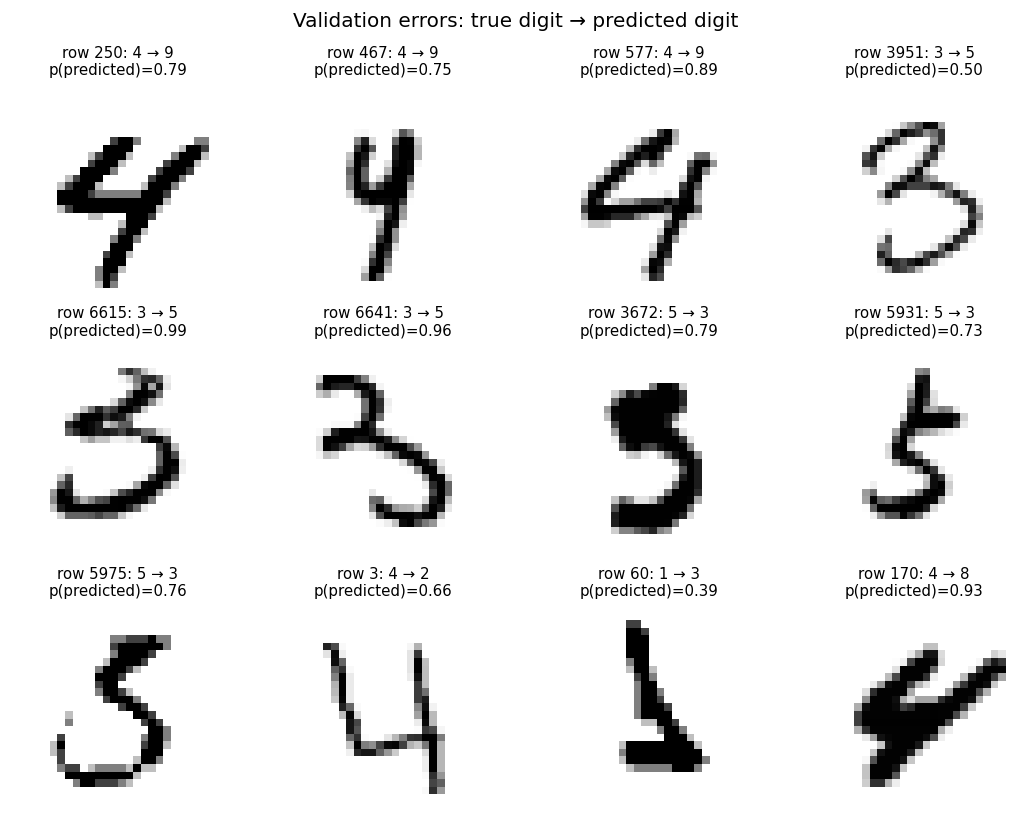

In [15]:
selected = []

for _, truth, prediction in pairs:
    selected.extend(errors[(errors.true_label == truth) & (errors.predicted_label == prediction)]
                    .sort_values("row_index").head(3).index.tolist())
selected = (selected + [i for i in errors.index if i not in selected])[:12]

if selected:
    fig, axes = plt.subplots(3, 4, figsize=(9, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, item) in zip(axes.flat, predictions.loc[selected].iterrows()):
        ax.imshow(X[int(item.row_index)].reshape(28, 28), cmap="gray_r", vmin=0, vmax=255)
        ax.set_title(f"row {int(item.row_index)}: {int(item.true_label)} → {int(item.predicted_label)}\n"
                     f"p(predicted)={item.confidence:.2f}", fontsize=9)
    fig.suptitle("Validation errors: true digit → predicted digit")
    fig.tight_layout()

## 8. Выводы

Baseline получил 91,33% accuracy и 0,9121 macro-F1.
Чаще всего путаются 4 → 9 и 3 ↔ 5.

## 9. Сохранение

In [16]:
reports_path.mkdir(parents=True, exist_ok=True)
(reports_path / "metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
predictions.to_csv(reports_path / "validation_predictions.csv", index=False)
split = pd.DataFrame({
    "row_index": np.concatenate([train_indices, validation_indices]),
    "partition": ["train"] * len(train_indices) + ["validation"] * len(validation_indices),
}).sort_values("row_index")
split.to_csv(reports_path / "split.csv", index=False)
manifest = {
    "data_sha256": data_sha256, "config": config,
    "split_method": split_method,
    "train_rows": len(train_indices), "validation_rows": len(validation_indices),
    "duplicate_rows_beyond_first": duplicate_rows,
    "groups_with_conflicting_labels": conflicting_groups,
    "overlapping_image_groups": 0,
    "trained_at_utc": checkpoint["trained_at_utc"],
    "training_seconds": checkpoint["training_seconds"],
    "iterations": checkpoint["iterations"], "converged": checkpoint["converged"],
}
(reports_path / "run.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print("Сохранены metrics.json, split.csv, validation_predictions.csv и run.json.")


Сохранены metrics.json, split.csv, validation_predictions.csv и run.json.
